# 01 - ZCZ prices and the Jun-Sep seasonal

Front-December corn futures (ZCZ), built by `cornsat.prices` from the Barchart daily files and stored in `data/processed/zcz_front_dec.parquet`. Prices are in cents per bushel; one contract is 5,000 bushels, so 1 cent = $50. Each season (`campaign`) is the ZCZ contract of that year, followed from January 2009 until its expiry.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cornsat.config import DATA_PROCESSED, ROOT

REPORTS = ROOT / "reports"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
C1, C2, C3, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 1.6,
})
pd.set_option("display.width", 160)

from cornsat import prices as P

front = pd.read_parquet(DATA_PROCESSED / "zcz_front_dec.parquet")
print(front.shape, front["date"].min().date(), "..", front["date"].max().date())
print("contracts:", front["contract"].nunique(), "| front series starts", P.FRONT_START.date())
front.tail(3)

(4492, 11) 2009-01-02 .. 2026-11-04
contracts: 18 | front series starts 2009-01-02

           date contract  campaign    open    high     low   close  volume      oi  days_to_expiry       ret
4489 2026-11-02    ZCZ26      2026  447.50  452.00  446.50  448.25  201884  758045             NaN  0.001116
4490 2026-11-03    ZCZ26      2026  448.00  448.50  441.25  442.50  212055  736544             NaN -0.012911
4491 2026-11-04    ZCZ26      2026  441.75  447.25  438.50  444.25  212688  734618             NaN  0.003947

## Front-December close, 2009-2026

The shaded bands are Jun-Sep, the window the backtest trades. The 2012 drought spike and the 2021-22 rally are the two big weather/supply episodes in the sample.

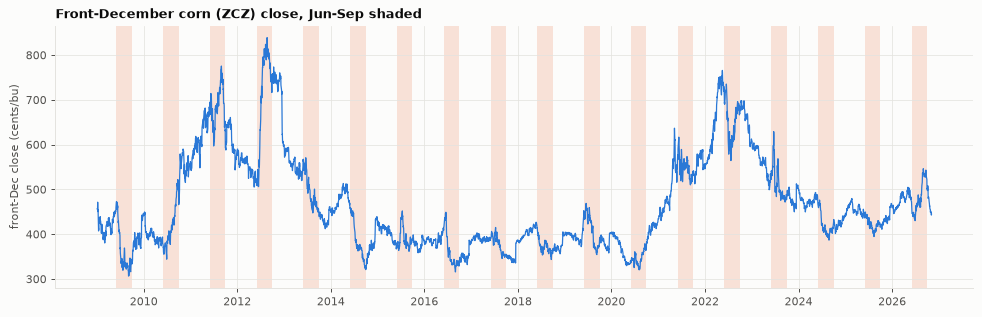

In [2]:
f = front.set_index("date")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(f.index, f["close"], color=C1, lw=1)
for y in range(2009, 2027):
    ax.axvspan(pd.Timestamp(y, 6, 1), pd.Timestamp(y, 9, 30), color=C2, alpha=0.18, lw=0)
ax.set_ylabel("front-Dec close (cents/bu)")
ax.set_title("Front-December corn (ZCZ) close, Jun-Sep shaded", loc="left")
fig.tight_layout()

## Average seasonal path, Jun 1 = 100

For every season the close is indexed to its first trading day on or after Jun 1, then the mean and median across seasons are drawn (thin lines are individual seasons).

day 121 (Sep 30): mean 96.0, median 91.5

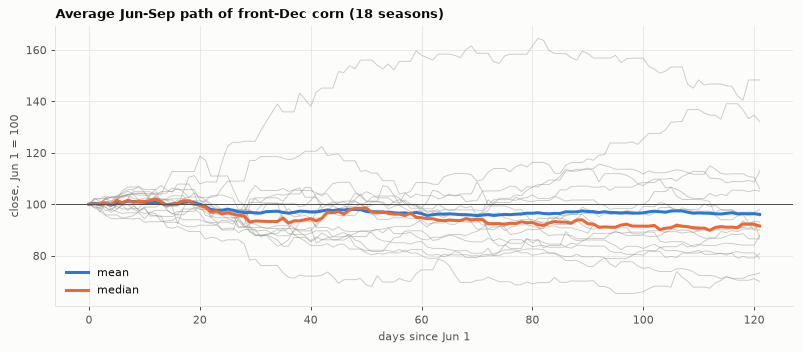

In [3]:
rows = []
for y, d in front.groupby("campaign"):
    d = d[(d["date"] >= pd.Timestamp(y, 6, 1)) & (d["date"] <= pd.Timestamp(y, 9, 30))]
    if d.empty:
        continue
    idx = d["close"].to_numpy() / d["close"].iloc[0] * 100
    rows.append(pd.DataFrame({"season": y, "day": (d["date"] - pd.Timestamp(y, 6, 1)).dt.days.to_numpy(),
                              "idx": idx, "date": d["date"].to_numpy()}))
path = pd.concat(rows)
piv = path.pivot_table(index="day", columns="season", values="idx").ffill()
mean, med = piv.mean(axis=1), piv.median(axis=1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(piv.index, piv.values, color=NEUTRAL, lw=0.7, alpha=0.45)
ax.plot(mean.index, mean, color=C1, lw=2.4, label="mean")
ax.plot(med.index, med, color=C2, lw=2.4, label="median")
ax.axhline(100, color=INK2, lw=0.8)
ax.set_xlabel("days since Jun 1")
ax.set_ylabel("close, Jun 1 = 100")
ax.set_title(f"Average Jun-Sep path of front-Dec corn ({piv.shape[1]} seasons)", loc="left")
ax.legend(loc="lower left")
fig.tight_layout()
print(f"day 121 (Sep 30): mean {mean.iloc[-1]:.1f}, median {med.iloc[-1]:.1f}")

## Jun 1 to Sep 30 return per season

fell in 13 of 18 seasons; mean -4.0%, median -8.5%
2014-2026 only: fell in 10 of 13; mean -7.0%

season      2009   2010  2011   2012   2013   2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
ret        -26.7   32.1 -12.8   48.3  -21.2  -30.0   5.1 -19.1  -8.7 -13.5 -12.2  12.9  -7.0  -2.0 -10.0  -8.2  -4.6   6.0
chg_cents -125.2  120.5 -87.0  246.2 -118.5 -137.8  18.8 -79.5 -34.0 -55.5 -53.8  43.2 -40.2 -14.0 -53.2 -38.0 -20.2  28.2

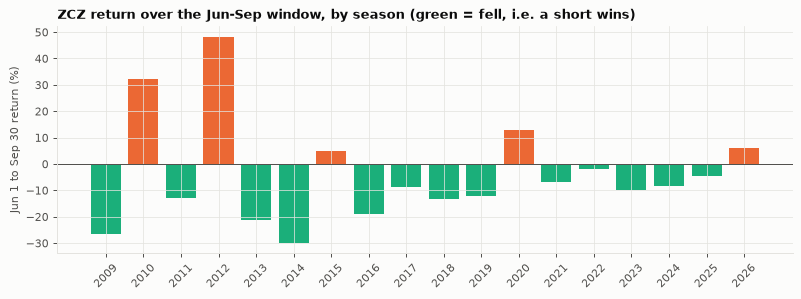

In [4]:
ret = []
for y, d in front.groupby("campaign"):
    d = d[(d["date"] >= pd.Timestamp(y, 6, 1)) & (d["date"] <= pd.Timestamp(y, 9, 30))]
    if len(d) > 1:
        ret.append((y, d["close"].iloc[-1] / d["close"].iloc[0] - 1, d["close"].iloc[-1] - d["close"].iloc[0]))
ret = pd.DataFrame(ret, columns=["season", "ret", "chg_cents"]).set_index("season")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(ret.index.astype(str), ret["ret"] * 100, color=[C3 if r < 0 else C2 for r in ret["ret"]])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_ylabel("Jun 1 to Sep 30 return (%)")
ax.set_title("ZCZ return over the Jun-Sep window, by season (green = fell, i.e. a short wins)", loc="left")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
neg = int((ret["ret"] < 0).sum())
print(f"fell in {neg} of {len(ret)} seasons; mean {ret['ret'].mean() * 100:.1f}%, median {ret['ret'].median() * 100:.1f}%")
print(f"2014-2026 only: fell in {int((ret.loc[2014:, 'ret'] < 0).sum())} of {len(ret.loc[2014:])}; mean {ret.loc[2014:, 'ret'].mean() * 100:.1f}%")
(ret * [100, 1]).round(1).T

## Takeaway: the weather premium decays

Corn futures carry a **weather risk premium** into June: the market prices the chance of a drought before the crop is made. In most years the weather is fine, the premium bleeds out, and the December contract drifts lower into harvest. In this sample the front-Dec contract fell between Jun 1 and Sep 30 in 13 of 18 seasons (10 of 13 in the 2014-2026 trading window). The median path ends near 91.5 and the mean near 96.0 (Jun 1 = 100); the mean is higher than the median because the few drought or supply-shock years (2010, 2012, 2020) rally hard, which is exactly the tail a long position is paying for.

This is the known seasonal behind the one strategy that works in the backtest (always short Jun-Sep, +$24,035 over 13 seasons, 10 of 13 positive). It is not something this project discovered: it needs no satellite, weather or USDA data, and with 13 seasons it is a short sample. Any model strategy has to beat it, and none does (see `04_backtest.ipynb`).